In [4]:
import numpy as np
import pandas as pd

In [5]:
df = pd.read_csv(
    '/content/drive/MyDrive/project NLP/processed_data.csv',
    encoding='utf-8',
    encoding_errors='ignore'
)
#Used to read text correctly, especially Arabic characters.
#Ignores broken or unsupported characters instead of stopping the code.
#يحدد طريقة قراءة النصوص والحروف بشكل صحيح، خاصة اللغة العربية
#يتجاهل أي حرف أو رمز فيه مشكلة بدل ما يوقف الكود


df.head()


,Title,Content,Link,Category
0,تيرتل تري لابز للتقنيات الحيويه تحصل علي تمويل...,جاءت جوله التمويل التمهيديه الاولي للشركه بقيا...,https://ryadiybusiness.com/%d8%aa%d9%8a%d8%b1%...,ريادة أعمال
1,تعد دراسه الجدوي لمشروعك الناشء 6 عوامل اساسيه,تعد دراسه الجدوي متطلبا اساسيا لنجاح اي مشروع ...,https://ryadiybusiness.com/%d9%83%d9%8a%d9%81-...,ريادة أعمال
2,منح جاءزه نوبل الطب لاكتشاف مجال التهاب الكبد ...,وقالت لجنه نوبل للمره الاولي التاريخ يمكن الان...,https://arabic.sputniknews.com/science/2020100...,علوم وتكنولوجيا
3,هيءه الغذاء والدواء الامريكيه لقاح مودرنا حقق ...,نشرت الوكاله وثاءق علي الانترنت اعدها موظفوها ...,https://arabic.sputniknews.com/world/202012151...,علوم وتكنولوجيا
4,حظر بروتين الجهاز المناعي يساعد علي محاربه عدو...,دراسه حديثه قام فريق العلماء جونز هوبكنز ميديس...,https://arabic.rt.com//technology/1161864-%D8%...,علوم وتكنولوجيا


In [6]:
print(df.shape)

(8399, 4)


In [7]:
df.columns

Index(['Title', 'Content', 'Link', 'Category'], dtype='object')

هنا يوضح نوع البيانات  وعددها و هل فيه مسينق داتا او لا


In [41]:
df.info()
# عندنا هنا بالكونتنت ٢٢ مسينق فاليو

<class 'pandas.core.frame.DataFrame'>
Index: 8386 entries, 0 to 8398
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Title     8386 non-null   object
 1   Content   8386 non-null   object
 2   Category  8386 non-null   object
 3   text      8386 non-null   object
dtypes: object(4)
memory usage: 327.6+ KB


In [42]:
df.isnull().sum()
#Checks for missing (empty) values in the dataset and counts them in each column.
#يفحص هل فيه بيانات ناقصة (فارغة) داخل الداتا، ويحسب عددها بكل عمود

,0
Title,0
Content,0
Category,0
text,0


هنا توزيع الفئات وهل هي بالنس الداتا سيت او نوت بالنس
وطبعا طلعت بالنس داتا سيت

In [43]:
df['Category'].value_counts()

,count
Category,
علوم وتكنولوجيا,2800
أخرى,2796
ريادة أعمال,2790


هنا مرحلة تنظيف البيانات  **Data Cleaning**

In [11]:
df = df.drop(columns=['Link'])

In [12]:
df.columns

Index(['Title', 'Content', 'Category'], dtype='object')

In [13]:
# بنحذف الصفوف الناقصة
df = df.dropna()

In [14]:
df.isnull().sum()

,0
Title,0
Content,0
Category,0


In [15]:
# عدد البيانات بعد تنظيف القيم الناقصه من الكونتنت تغير عدد البيانات بعد حذف ٢٢ سطر
df.shape

(8386, 3)

**دمج Title + Content**
سوينا كذا عشان نعطي النموذج نص أقوى
بدل ما يعتمد على محتوى فقط

In [16]:
df['text'] = df['Title'] + " " + df['Content']

In [17]:
df[['text', 'Category']].head()

,text,Category
0,تيرتل تري لابز للتقنيات الحيويه تحصل علي تمويل...,ريادة أعمال
1,تعد دراسه الجدوي لمشروعك الناشء 6 عوامل اساسيه...,ريادة أعمال
2,منح جاءزه نوبل الطب لاكتشاف مجال التهاب الكبد ...,علوم وتكنولوجيا
3,هيءه الغذاء والدواء الامريكيه لقاح مودرنا حقق ...,علوم وتكنولوجيا
4,حظر بروتين الجهاز المناعي يساعد علي محاربه عدو...,علوم وتكنولوجيا




*   The Title and Content columns were combined to create a richer text representation, improving the model’s ability to understand and classify the data more accurately.
*  👆🏻 تم دمج عمودي العنوان والمحتوى لإنشاء نص أكثر غنى، مما يساعد النموذج على فهم البيانات وتصنيفها بدقة أعلى


**Ttext Preprocessing**  مرحلة

In [18]:
# هنا نحذف الارقام والرموز مثل السلاش والكوما removing symbols
import re

def clean_text(text):
    # إزالة الأرقام
    text = re.sub(r'\d+', '', text)

    # إزالة الرموز
    text = re.sub(r'[^\w\s]', '', text)

    return text

df['text'] = df['text'].apply(clean_text)

In [19]:
# هنا نحذف الحركات remove_diacritics
import re

def remove_diacritics(text):
    arabic_diacritics = re.compile("""
                             ّ    | # تشديد
                             َ    | # فتحة
                             ً    | # تنوين فتح
                             ُ    | # ضمة
                             ٌ    | # تنوين ضم
                             ِ    | # كسرة
                             ٍ    | # تنوين كسر
                             ْ    | # سكون
                             ـ     # تطويل
                         """, re.VERBOSE)

    return re.sub(arabic_diacritics, '', text)

df['text'] = df['text'].apply(remove_diacritics)

In [20]:
# هنا نوحد الحروف عشان مايتخربط بالتعليم normalizing characters
def normalize_arabic(text):
    text = re.sub("[إأآا]", "ا", text)
    text = re.sub("ى", "ي", text)
    text = re.sub("ؤ", "ء", text)
    text = re.sub("ئ", "ء", text)
    return text

df['text'] = df['text'].apply(normalize_arabic)

In [21]:
# ازلنا كلمات التوقف الي حروف الجر وغيرها Removing Stppwords
from nltk.corpus import stopwords
import nltk

nltk.download('stopwords')

arabic_stopwords = set(stopwords.words('arabic'))

def remove_stopwords(text):
    words = text.split()
    return " ".join([word for word in words if word not in arabic_stopwords])

df['text'] = df['text'].apply(remove_stopwords)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [22]:
df['text'].head()

,text
0,تيرتل تري لابز للتقنيات الحيويه تحصل علي تمويل...
1,تعد دراسه الجدوي لمشروعك الناشء عوامل اساسيه ت...
2,منح جاءزه نوبل الطب لاكتشاف مجال التهاب الكبد ...
3,هيءه الغذاء والدواء الامريكيه لقاح مودرنا حقق ...
4,حظر بروتين الجهاز المناعي يساعد علي محاربه عدو...


👆🏻
Text preprocessing was applied to clean and normalize Arabic text by removing symbols, diacritics, and normalizing characters to improve model performance.

تم تطبيق معالجة مسبقة للنصوص لتنظيف وتوحيد النص العربي من خلال إزالة الرموز والتشكيل وتوحيد الحروف لتحسين أداء النموذج


**TF-IDF**👇🏻

 يبني قاموس كلمات Vocabulary

TF-IDF converts Arabic text into numerical features by selecting the most important 5000 words to help the AI model understand and classify the text data efficiently.

يقوم TF-IDF بتحويل النصوص العربية إلى قيم رقمية من خلال اختيار أهم 5000 كلمة لمساعدة نموذج الذكاء الاصطناعي على فهم البيانات النصية وتصنيفها بكفاءة.

 لتحويل النصوص إلى أرقام
 لأن الموديل مايفهم النص مباشرة مثل
	•	“ذكاء اصطناعي”
	•	“رياضة”
	•	“تقنية”

هو يفهم أرقام فقط

In [44]:
# استيراد أداة TF-IDF
# لتحويل النصوص إلى أرقام
from sklearn.feature_extraction.text import TfidfVectorizer

# إنشاء محوّل TF-IDF
# max_features=5000 يعني نختار أهم 5000 كلمة فقط حتى لا تكون البيانات ضخمة جدًا
tfidf = TfidfVectorizer(max_features=5000)

# X تمثل النصوص بعد تحويلها إلى أرقام
X = tfidf.fit_transform(df['text'])

# y تمثل التصنيف الصحيح لكل خبر
y = df['Category']

# عرض شكل البيانات بعد التحويل
print(X.shape)
print(y.shape)

(8386, 5000)
(8386,)


# Training Model (تدريب النموذج)
# Logistic Regression

In [24]:
# استيراد مكتبة أداة تقسيم البيانات التدريب ٨٠ والاختبار  ٢٠ا
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
     )
# 20% test data, and random_state fixes the split so results stay the same
#  للاختبارrandom_state يثبت التقسيم عشان النتائج تكون نفسها كل مرة

In [25]:
# استيراد نموذج Logistic Regression
from sklearn.linear_model import LogisticRegression

In [45]:
# إنشاء نموذج والالف هي عدد محاولات التعلم عشان يوصل لأفضل أداءCreate the Logistic Regression
lr_model = LogisticRegression(max_iter=1000)

In [27]:
# Train the model using the training data  تأكيد إن المودل انبنى وتدرّب بنجاح
# تدريب النموذج باستخدام بيانات التدريب
lr_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [28]:
# وطبعا التي اف هي الفتشرز ي TF-IDF<<< features - 50000 والخمس الاف هي الـ frows - 9896 هنا تقسمت البيانات اولا لللتسع الاف عدد المقالات الي الـ
print(X_train.shape)

(6708, 5000)


In [29]:
# Predict on test data
y_pred = lr_model.predict(X_test)

# توقع الفئات على بيانات الاختبار

In [30]:
# Calculate accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# حساب دقة النموذج لمعرفة كم نسبة التوقعات الصحيحة

Accuracy: 0.9833134684147795


In [31]:
# Detailed performance report
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

# يعطيك precision, recall, f1-score لكل فئة

                 precision    recall  f1-score   support

           أخرى       0.99      0.99      0.99       568
    ريادة أعمال       0.98      0.98      0.98       536
علوم وتكنولوجيا       0.98      0.98      0.98       574

       accuracy                           0.98      1678
      macro avg       0.98      0.98      0.98      1678
   weighted avg       0.98      0.98      0.98      1678



In [32]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)
 # يوضح كم توقع صح للارقام الكبيرة وكم أخطأ لارقام الصغيرة مثل الواحد والثلاثه وطبعا الرقم الثالث يعني انحسبت الفئه الثالثه اخرى


[[562   1   5]
 [  2 525   9]
 [  1  10 563]]


In [46]:
!pip install arabic-reshaper python-bidi
#يقوم بتثبيت مكتبات تساعد على عرض النص العربي بشكل صحيح داخل الرسوم أو المخرجات
#Installs libraries used to display Arabic text correctly in visualizations and outputs.

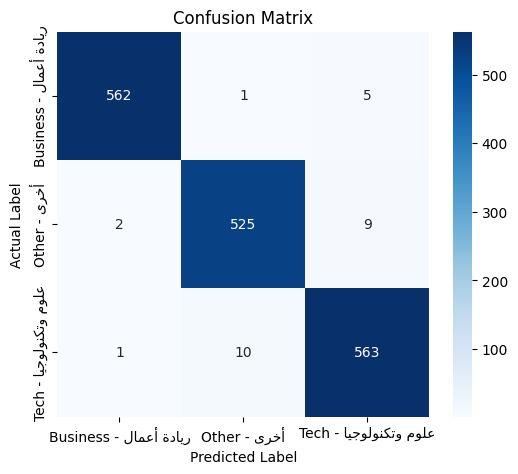

In [34]:
#حملنا مكتبات للغه العربيه عشان يطلع العرض حلو
#مكتبه ماتبوليب وسي بورن  للتصور وللكونفيوشن ماتريكس
import seaborn as sns
import matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display

# دالة تضبط العربي
def fix_arabic(text):
    reshaped = arabic_reshaper.reshape(text)
    return get_display(reshaped)

# أسماء الفئات (بعد التصحيح)
labels = ['ريادة أعمال - Business', 'أخرى - Other', 'علوم وتكنولوجيا - Tech']
labels = [fix_arabic(label) for label in labels]

plt.figure(figsize=(6,5))

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=labels,
            yticklabels=labels)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()
plt.show()

# Naive Bayes model

In [35]:

from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer

nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('model', MultinomialNB())
])


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['Category'], test_size=0.2, random_state=42
)

In [37]:
nb_pipeline.fit(X_train, y_train)

y_pred_nb = nb_pipeline.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.9737783075089392


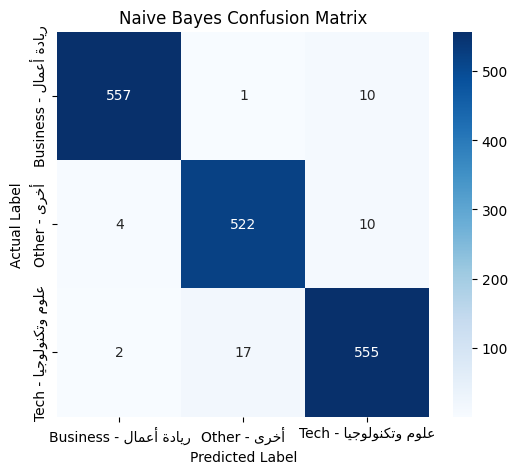

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# إنشاء Confusion Matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

labels = ['ريادة أعمال - Business', 'أخرى - Other', 'علوم وتكنولوجيا - Tech']
labels = [fix_arabic(label) for label in labels]


# رسم Confusion Matrix
plt.figure(figsize=(6,5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Naive Bayes Confusion Matrix")

plt.show()

# SVM model

In [52]:
# استيراد المودل
from sklearn.svm import LinearSVC

# إنشاء Pipeline (TF-IDF + SVM)
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),  # تحويل النص إلى أرقام
    ('model', LinearSVC())  # مودل SVM
])

# تدريب النموذج
svm_pipeline.fit(X_train, y_train)

# التنبؤ
y_pred_svm = svm_pipeline.predict(X_test)

# حساب الدقة
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

SVM Accuracy: 0.9856972586412396


In [53]:
from sklearn.metrics import classification_report, confusion_matrix

# تقرير مفصل
print(classification_report(y_test, y_pred_svm))

# مصفوفة الأخطاء
cm_svm = confusion_matrix(y_test, y_pred_svm)
print(cm_svm)

                 precision    recall  f1-score   support

           أخرى       1.00      1.00      1.00       568
    ريادة أعمال       0.98      0.98      0.98       536
علوم وتكنولوجيا       0.98      0.98      0.98       574

       accuracy                           0.99      1678
      macro avg       0.99      0.99      0.99      1678
   weighted avg       0.99      0.99      0.99      1678

[[566   2   0]
 [  1 526   9]
 [  1  11 562]]


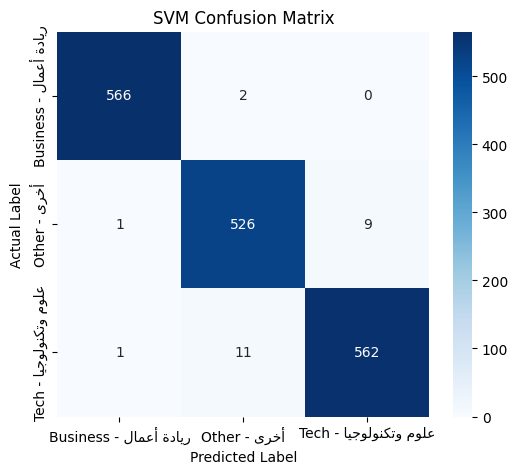

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

def fix_arabic(text):
    reshaped = arabic_reshaper.reshape(text)
    return get_display(reshaped)

# أسماء الفئات (بعد التصحيح)
labels = ['ريادة أعمال - Business', 'أخرى - Other', 'علوم وتكنولوجيا - Tech']
labels = [fix_arabic(label) for label in labels]

plt.figure(figsize=(6,5))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")

plt.show()

# Deep Learning
أما الـ LSTM لازم:
	1.	يحول الكلمات لأرقام
	2.	يوحد طول الجمل
	3.	يبني شبكة عصبية
	4.	يحدد الطبقات
	5.	يدرب المودل

عشان كذا الأكواد أكثر شوي

In [55]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [56]:
# تحويل التصنيفات إلى أرقام
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(df['Category'])

In [57]:
# تحويل النصوص إلى أرقام
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(df['text'])

X_seq = tokenizer.texts_to_sequences(df['text'])

# توحيد طول النصوص
X_pad = pad_sequences(X_seq, maxlen=100)

In [58]:
# تقسيم البيانات
X_train, X_test, y_train, y_test = train_test_split(
    X_pad,
    y_encoded,
    test_size=0.2,
    random_state=42
)

# LSTM Model

In [59]:
model = Sequential([
    Embedding(input_dim=5000, output_dim=64, input_length=100),
    LSTM(64),
    Dense(3, activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [60]:
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [61]:
# التدريب
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
168/168 ━━━━━━━━━━━━━━━━━━━━ 23s 104ms/step - accuracy: 0.8645 - loss: 0.3558 - val_accuracy: 0.9747 - val_loss: 0.0987
Epoch 2/5
168/168 ━━━━━━━━━━━━━━━━━━━━ 19s 113ms/step - accuracy: 0.9855 - loss: 0.0620 - val_accuracy: 0.9762 - val_loss: 0.0828
Epoch 3/5
168/168 ━━━━━━━━━━━━━━━━━━━━ 23s 134ms/step - accuracy: 0.9862 - loss: 0.0575 - val_accuracy: 0.9806 - val_loss: 0.0663
Epoch 4/5
168/168 ━━━━━━━━━━━━━━━━━━━━ 30s 66ms/step - accuracy: 0.9957 - loss: 0.0199 - val_accuracy: 0.9501 - val_loss: 0.2551
Epoch 5/5
168/168 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.9948 - loss: 0.0224 - val_accuracy: 0.9687 - val_loss: 0.1470


In [62]:
#التقييم
loss, accuracy = model.evaluate(X_test, y_test)

print("LSTM Accuracy:", accuracy)

53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9601 - loss: 0.1902
LSTM Accuracy: 0.9600715041160583


53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step


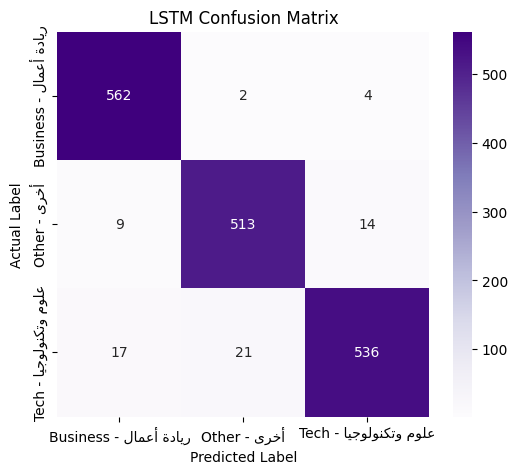

In [63]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# التنبؤ على بيانات الاختبار
y_pred_probs = model.predict(X_test)

# تحويل الاحتمالات إلى تصنيفات
y_pred_lstm = np.argmax(y_pred_probs, axis=1)

# إنشاء Confusion Matrix
cm_lstm = confusion_matrix(y_test, y_pred_lstm)

# أسماء الفئات (بعد التصحيح)
labels = ['ريادة أعمال - Business', 'أخرى - Other', 'علوم وتكنولوجيا - Tech']
labels = [fix_arabic(label) for label in labels]

# رسم Confusion Matrix
plt.figure(figsize=(6,5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt='d',
    cmap='Purples',   # لون مختلف عن المودلات السابقة
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM Confusion Matrix")

plt.show()

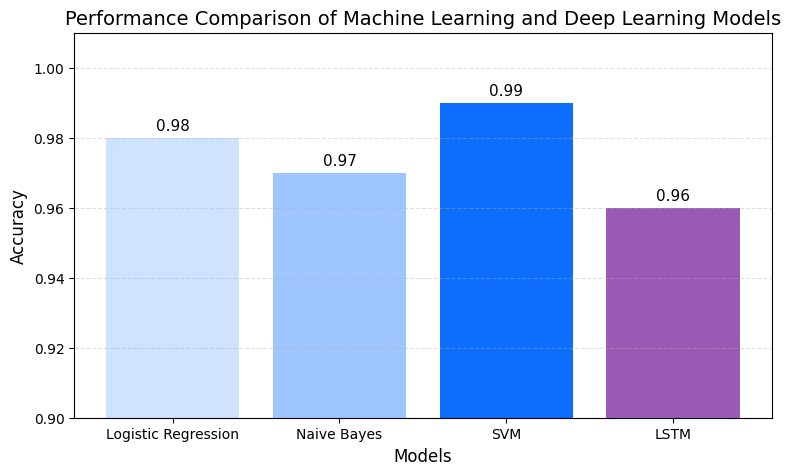

In [67]:
import matplotlib.pyplot as plt

# أسماء النماذج
models = ['Logistic Regression', 'Naive Bayes', 'SVM', 'LSTM']

# قيم الدقة
accuracies = [0.98, 0.97, 0.99, 0.96]

# الألوان
colors = ['#cfe2ff', '#9ec5fe', '#0d6efd', '#9b59b6']

# رسم Bar Chart
plt.figure(figsize=(9,5))

bars = plt.bar(models, accuracies, color=colors)

# كتابة قيمة الدقة فوق الأعمدة
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.002,
        f'{yval:.2f}',
        ha='center',
        fontsize=11
    )

# تنسيق الرسم
plt.ylim(0.90, 1.01)

plt.xlabel('Models', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Performance Comparison of Machine Learning and Deep Learning Models', fontsize=14)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()